# Figure 3: vaccination environments in the multilayer contact network

Builds the complete Fig. 3 (panels A–G) as one vector PDF, 183 mm wide (Nature double column).

**Files needed in the same folder as this notebook**

| File | Used for |
|---|---|
| `multilayer-network.js` | schematic in panel A |
| `fig4_plotdata.parquet` | data for panels B–G |
| `fonts/` (recommended) | Liberation Sans, used when Arial is not installed (same folder as for Fig. 4) |

**Requirements**

- [Node.js](https://nodejs.org) on the system path (runs the schematic script)
- Python packages: `numpy pandas matplotlib pyarrow pymupdf`

**Output:** `figure3.pdf` (vector, place at 100% width) and `figure3.png` (preview), written next to the notebook.

The JS file is never edited. The notebook passes it a few settings when it runs (colours, plane spacing, node size) so that panel A matches panels B–G.

In [1]:
# Uncomment to install the Python packages into this kernel
# %pip install numpy pandas matplotlib pyarrow pymupdf

## 1. Setup

In [3]:
from __future__ import annotations

import re
import shutil
import subprocess
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch, Patch, Rectangle
from matplotlib.ticker import FuncFormatter, MultipleLocator
import pymupdf
from IPython.display import Image, display

HERE = Path.cwd()

JS_FILE = HERE / "multilayer-network.js"
DATA = HERE / "fig3_plotdata.parquet"

OUT_STEM = HERE / "figure3"


NODE = shutil.which("node")
for f in (JS_FILE, DATA):
    if not f.exists():
        raise FileNotFoundError(f"Put {f.name} in {HERE}")
if NODE is None:
    raise RuntimeError("Node.js not found. Install it from https://nodejs.org and restart the kernel.")
print("Node.js:", NODE)

Node.js: /appl/manual_installations/software/jupyterhub/live/miniconda/bin/node


## 2. Style
Font sizes are the printed sizes (Nature: 5–7 pt text). Arial is used if installed; otherwise Liberation Sans (its metric twin) from the `fonts/` folder, so the figure never falls back to DejaVu Sans.

In [4]:
UNVAX = "#e15759"
VAX = "#4e79a7"
COL = {"Unvaccinated": UNVAX, "Vaccinated": VAX}
INK = "#222222"
MUTED = "#555555"
FRAME = "#cfcfcf"
LAYER_LABEL = "#5f6875"
BLOCK_GREY = "#ededed"   # background of the cross-layer panels F and G

FS_HEAD = 9.0      # panel headings, "A. Contact network"
FS_LABEL = 7.2     # axis titles
FS_TICK = 6.5      # tick labels
FS_SMALL = 6.0     # text inside insets
FS_LAYER = 6.5     # layer names in panel A


def first_available_font(candidates):
    for name in candidates:
        try:
            font_manager.findfont(name, fallback_to_default=False)
            return name
        except ValueError:
            continue
    return "DejaVu Sans"


# Fonts shipped next to the notebook (no install needed).
if (HERE / "fonts").is_dir():
    for path in sorted((HERE / "fonts").glob("*.ttf")):
        font_manager.fontManager.addfont(str(path))

FONT = first_available_font(["Arial", "Liberation Sans", "Helvetica", "DejaVu Sans"])
print("Font:", FONT)

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": [FONT],
    "mathtext.fontset": "custom",
    "mathtext.rm": FONT,
    "mathtext.it": f"{FONT}:italic",
    "mathtext.bf": f"{FONT}:bold",
    "mathtext.cal": FONT,                 # avoids a harmless "cursive" font warning
    "mathtext.fallback": "stixsans",
    "font.size": FS_LABEL,
    "axes.labelsize": FS_LABEL,
    "xtick.labelsize": FS_TICK,
    "ytick.labelsize": FS_TICK,
    "axes.edgecolor": INK,
    "axes.labelcolor": INK,
    "xtick.color": INK,
    "ytick.color": INK,
    "text.color": INK,
    "axes.linewidth": 0.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size": 2.0,
    "ytick.major.size": 2.0,
    "xtick.major.pad": 1.6,
    "ytick.major.pad": 1.6,
    "axes.labelpad": 2.2,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "pdf.fonttype": 42,          # editable text in the PDF
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

NUM = FuncFormatter(lambda v, _=None: f"{v:g}".replace("-", "−"))

Font: DejaVu Sans


## 3. Layout
All positions are in inches, origin bottom-left. Two rows of three panels, one shared y-axis title per row:

```
A. Contact network | B. Work      | C. Education
D. Household       | E. Family    | F. Mean across layers   ┐ light grey block:
                                  | G. Variance across layers ┘ cross-layer summaries
```

In [5]:
W = 7.20                     # 183 mm
L_MARGIN = 0.42
COL_GAPS = [0.44, 0.34]      # the second gap holds the edge of the F/G grey block
COL_WS = [2.06, 1.94, 1.83]
COL_XS = [L_MARGIN, L_MARGIN + COL_WS[0] + COL_GAPS[0],
          L_MARGIN + COL_WS[0] + COL_WS[1] + COL_GAPS[0] + COL_GAPS[1]]

TOP = 0.24
ROW_H = [1.72, 1.72]
ROW_GAP = 0.62
BOTTOM = 0.38
H = TOP + sum(ROW_H) + ROW_GAP + BOTTOM


def slot(row, col):
    # (x, y, w, h) of a panel's axes area
    y_top = H - TOP - sum(ROW_H[:row]) - row * ROW_GAP
    return COL_XS[col], y_top - ROW_H[row], COL_WS[col], ROW_H[row]


def add_ax(fig, x, y, w, h, **kw):
    return fig.add_axes([x / W, y / H, w / W, h / H], **kw)


def heading(fig, x_axes, y_top, letter, title):
    return fig.text(x_axes / W, (y_top + 0.08) / H, f"{letter}. {title}", ha="left",
                    va="baseline", fontsize=FS_HEAD, fontweight="bold")


def fig_ylabel(fig, x, y_mid, text, size=FS_LABEL):
    fig.text(x / W, y_mid / H, text, rotation=90, ha="center", va="center", fontsize=size)


def inset_frame(ax, x, y, w, h, fx, fy, fw, fh):
    ax.add_patch(Rectangle(((fx - x) / w, (fy - y) / h), fw / w, fh / h,
                           transform=ax.transAxes, facecolor="white",
                           edgecolor=FRAME, linewidth=0.5, zorder=3, clip_on=False))

## 4. Panel A: schematic
Runs `multilayer-network.js` with Node, then turns its SVG into vector PDF with PyMuPDF.

- The settings passed to the JS give it the figure's red and blue, space the four planes to fit the panel, and draw nodes 30% larger.
- The SVG's text is removed. The panel title and the layer names are set by matplotlib in the figure font. Each layer name runs up its plane's slanted left edge.
- PyMuPDF does not read CSS, so the SVG's style rules are written onto each element first. Line widths are raised slightly for print.

In [6]:
SVG_VIEW_X, SVG_W, SVG_H = 132, 1392, 1122
SVG_PLANE_BACK_LEFT_X, SVG_DEPTH_X, SVG_DEPTH_Y = 450, -300, 190
SVG_BACK_Y = [40, 332, 624, 916]
LAYER_NAMES = ["Work", "Education", "Household", "Family"]

A_X0 = 0.10
A_W = COL_XS[1] - 0.44 - A_X0      # clear of the row's y-axis title
A_H = A_W * SVG_H / SVG_W
A_TOP = H - TOP - 0.03

JS_SETTINGS = {                    # text in the JS -> value used here
    'red: "#EB5B55"': f'red: "{UNVAX.upper()}"',
    'blue: "#4D6FE8"': f'blue: "{VAX.upper()}"',
    "const HEIGHT = 1004;": f"const HEIGHT = {SVG_H};",
    "backY: [58, 295, 520, 762],": f"backY: {SVG_BACK_Y},",
    "const rx = mix(15, disc.rx, p);": "const rx = mix(19.5, disc.rx, p);",
    "const ry = mix(7, disc.ry, p);": "const ry = mix(9.1, disc.ry, p);",
    "nodeRadius: 0.037,": "nodeRadius: 0.048,",
    "familyRadius: 0.06,": "familyRadius: 0.078,",
    "const w = 19;\n  const h = 9;\n  const bevel = 7;":
        "const w = 24.7;\n  const h = 11.7;\n  const bevel = 9.1;",
}

PRINT_LINE_WIDTHS = {              # SVG class -> attributes for print
    "plane": {"stroke-width": "2.0"},
    "workplace-edge": {"stroke-width": "1.4"},
    "education-edge": {"stroke-width": "1.7"},
    "household-edge": {"stroke-width": "2.3"},
    "family-edge": {"stroke-width": "2.6"},
    "projection": {"stroke-width": "1.9"},
    "identity-red": {"stroke-width": "4.0", "stroke-opacity": "0.85"},
    "identity-blue": {"stroke-width": "4.0", "stroke-opacity": "0.85"},
}


def css_rules(svg):
    # Simple class rules from the SVG's <style> blocks: [(class, {prop: value})]
    rules = []
    for block in re.findall(r"<style>(.*?)</style>", svg, flags=re.S):
        for selectors, body in re.findall(r"([^{}]+)\{([^{}]*)\}", block):
            decl = {}
            for item in body.split(";"):
                if ":" in item:
                    k, v = item.split(":", 1)
                    decl[k.strip()] = " ".join(v.split())
            for sel in selectors.split(","):
                sel = sel.strip()
                if sel.startswith(".") and " " not in sel:
                    rules.append((sel[1:], decl))
    return rules


def inline_styles(svg, overrides):
    # Write class styles onto each element as attributes, then drop <style>
    rules = css_rules(svg) + list(overrides.items())

    def apply(m):
        tag = m.group(0)
        cls = re.search(r'class="([^"]*)"', tag)
        if not cls:
            return tag
        classes = cls.group(1).split()
        merged = {}
        for name, decl in rules:
            if name in classes:
                merged.update(decl)
        merged.pop("font", None)
        extra = "".join(f' {k}="{v}"' for k, v in merged.items() if f' {k}="' not in tag)
        return tag[:-2] + extra + " />" if tag.endswith("/>") else tag[:-1] + extra + ">"

    svg = re.sub(r"<(polygon|line|ellipse|rect|g)\b[^>]*>", apply, svg)
    return re.sub(r"<style>.*?</style>", "", svg, flags=re.S)


def thicker_node_outlines(svg):
    def bump(m):
        return (m.group(0).replace('stroke-width="1.3"', 'stroke-width="1.9"')
                          .replace('stroke-width="1"', 'stroke-width="1.5"'))
    return re.sub(r'<g class="(upper|family)-node[^"]*".*?</g>', bump, svg, flags=re.S)


def close_polygons(svg):
    # PyMuPDF before 1.28 does not stroke the closing side of an SVG <polygon>
    # (the left edge of each plane, one side of each family hexagon).
    # A <path> ending in "Z" draws every side in all versions.
    number = r"[-+]?(?:\d*\.\d+|\d+\.?)(?:[eE][-+]?\d+)?"

    def to_path(m):
        tag = m.group(0)
        points = re.search(r'\spoints="([^"]*)"', tag)
        nums = re.findall(number, points.group(1))
        xy = [f"{nums[i]},{nums[i + 1]}" for i in range(0, len(nums) - 1, 2)]
        tag = tag.replace(points.group(0), f' d="M {" L ".join(xy)} Z"')
        return "<path" + tag[len("<polygon"):]

    return re.sub(r"<polygon\b[^>]*>", to_path, svg).replace("</polygon>", "</path>")


def build_schematic(workdir):
    # Returns the panel-A schematic as an open single-page PDF document
    js = JS_FILE.read_text(encoding="utf8")
    for old, new in JS_SETTINGS.items():
        if old not in js:
            raise RuntimeError(f"Setting not found in the JS (was the file changed?): {old!r}")
        js = js.replace(old, new)
    js_tmp = workdir / "multilayer-network.js"
    js_tmp.write_text(js, encoding="utf8")
    svg_path = workdir / "panelA.svg"
    run = subprocess.run([NODE, str(js_tmp), str(svg_path)], capture_output=True, text=True)
    if run.returncode != 0:
        raise RuntimeError("Node failed:\n" + run.stderr)

    svg = svg_path.read_text(encoding="utf8")
    svg = re.sub(r"<text\b[^>]*>.*?</text>", "", svg, flags=re.S)
    svg = thicker_node_outlines(inline_styles(svg, PRINT_LINE_WIDTHS))
    svg = close_polygons(svg)
    as_svg = pymupdf.open(stream=svg.encode("utf8"), filetype="svg")
    return pymupdf.open("pdf", as_svg.convert_to_pdf())


def svg_to_fig(xs, ys):
    return (A_X0 + (xs - SVG_VIEW_X) / SVG_W * A_W, A_TOP - ys / SVG_H * A_H)


def panel_a_text(fig):
    heading(fig, COL_XS[0], H - TOP, "A", "Contact network")
    # Each layer name runs up its plane's slanted left edge, just outside it,
    # ending 30% of the way down from the back-left corner (clear of the
    # vertical identity lines).
    angle = np.degrees(np.arctan2(SVG_DEPTH_Y, -SVG_DEPTH_X))
    normal = np.array([-np.sin(np.radians(angle)), np.cos(np.radians(angle))])
    for name, back_y in zip(LAYER_NAMES, SVG_BACK_Y):
        t = 0.30
        xs = SVG_PLANE_BACK_LEFT_X + t * SVG_DEPTH_X
        ys = back_y + t * SVG_DEPTH_Y
        x, y = np.array(svg_to_fig(xs, ys)) + 0.025 * normal
        fig.text(x / W, y / H, name, ha="right", va="bottom", rotation=angle,
                 rotation_mode="anchor", fontsize=FS_LAYER, color=LAYER_LABEL)

## 5. Data access and drawing helpers
Bars show the percentage of individuals within each vaccination-status group in each bin; each distribution sums to 100%.

In [7]:
def main_hist(d, panel, status):
    s = d[(d.row_type == "main_hist") & (d.panel == panel) & (d.status == status)]
    s = s.sort_values("bin_left")
    share = 100 * s["density"].to_numpy(float) * s["bin_width"].to_numpy(float)
    return s["bin_left"].to_numpy(float), s["bin_width"].to_numpy(float), share


def exact_pmf(d, layer, c, status):
    s = d[(d.row_type == "inset_exact") & (d.layer == layer)
          & (d.group_size == float(c)) & (d.status == status)].sort_values("x_value")
    return s["x_value"].to_numpy(float), 100 * s["probability"].to_numpy(float)


def large_hist(d, layer, status):
    s = d[(d.row_type == "inset_fraction_hist") & (d.layer == layer)
          & (d.status == status)].sort_values("bin_left")
    share = 100 * s["density"].to_numpy(float) * s["bin_width"].to_numpy(float)
    return s["bin_left"].to_numpy(float), s["bin_width"].to_numpy(float), share


def draw_main(ax, d, panel, lw=0.25):
    for st in ["Unvaccinated", "Vaccinated"]:
        left, width, share = main_hist(d, panel, st)
        ax.bar(left, share, width=width, align="edge", color=COL[st], alpha=0.62,
               edgecolor="white", linewidth=lw)


def style_main(ax, xlabel, ylim, ystep, xlim=(0, 1), xstep=0.2, ylabel=True):
    ax.set_xlim(*xlim)
    ax.set_ylim(0, ylim)
    ax.xaxis.set_major_locator(MultipleLocator(xstep))
    ax.yaxis.set_major_locator(MultipleLocator(ystep))
    ax.xaxis.set_major_formatter(NUM)
    ax.yaxis.set_major_formatter(NUM)
    ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel("Share of individuals (%)")


def mini_title(ax, text, fs):
    ax.text(0.5, 0.98, text, transform=ax.transAxes, ha="center", va="top",
            fontsize=fs, zorder=10)


def draw_pmf(ax, d, layer, c, show_yticks, xlabel=None, fs=FS_SMALL):
    w = 0.40
    for st, off in [("Unvaccinated", -w / 2), ("Vaccinated", w / 2)]:
        x, p = exact_pmf(d, layer, c, st)
        ax.bar(x + off, p, width=w, color=COL[st], alpha=0.88, edgecolor="white",
               linewidth=0.2)
    ax.set_xlim(-0.6, c - 1 + 0.6)
    ax.set_xticks(np.arange(c))
    ax.set_ylim(0, 100)
    ax.set_yticks([0, 50, 100])
    ax.tick_params(labelsize=fs, length=1.8, pad=1.2)
    if not show_yticks:
        ax.tick_params(labelleft=False)
    mini_title(ax, rf"$c={c}$", fs)
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=fs + 0.5, labelpad=1.8)


def draw_large(ax, d, layer, ylim, ystep, xlabel, fs=FS_SMALL):
    for st in ["Unvaccinated", "Vaccinated"]:
        left, width, share = large_hist(d, layer, st)
        ax.bar(left, share, width=width, align="edge", color=COL[st], alpha=0.62,
               edgecolor="white", linewidth=0.2)
    ax.set_xlim(0, 1)
    ax.set_xticks([0, 0.5, 1])
    ax.xaxis.set_major_formatter(NUM)
    ax.set_ylim(0, ylim)
    ax.yaxis.set_major_locator(MultipleLocator(ystep))
    ax.tick_params(labelsize=fs, length=1.8, pad=1.2)
    mini_title(ax, r"$c\geq 6$", fs)
    ax.set_xlabel(xlabel, fontsize=FS_LABEL if fs >= FS_TICK else fs + 0.5, labelpad=1.8)

## 6. Panels B–G

In [8]:
def panel_b(fig, d):
    x, y, w, h = slot(0, 1)
    ax = add_ax(fig, x, y, w, h)
    draw_main(ax, d, "B")
    style_main(ax, r"Vacc. fraction, $f_{\mathrm{work}}(i)$", 30, 10)
    heading(fig, x, y + h, "B", "Work")

    # Inset: small workplaces, 3 + 2 small plots
    ph, tick_h, gap_r, xlab_h = 0.31, 0.11, 0.04, 0.11
    pad_t, pad_b = 0.04, 0.04
    fh = pad_t + ph + tick_h + gap_r + ph + tick_h + xlab_h + pad_b
    fx, fw = x + 0.04, 1.54
    fy = y + h - fh + 0.02
    inset_frame(ax, x, y, w, h, fx, fy, fw, fh)

    in_l = fx + 0.31
    in_r = fx + fw - 0.05
    gap = 0.07
    mw = (in_r - in_l - 2 * gap) / 3
    row1_y = fy + fh - pad_t - ph
    row2_y = row1_y - tick_h - gap_r - ph
    for k, c in enumerate([2, 3, 4]):
        a = add_ax(fig, in_l + k * (mw + gap), row1_y, mw, ph, zorder=4)
        draw_pmf(a, d, "work", c, show_yticks=(k == 0))
    a5 = add_ax(fig, in_l, row2_y, mw, ph, zorder=4)
    draw_pmf(a5, d, "work", 5, show_yticks=True, xlabel="Vacc. co-workers")
    big_l = in_l + mw + 0.22
    a6 = add_ax(fig, big_l, row2_y, in_r - big_l, ph, zorder=4)
    draw_large(a6, d, "work", 40, 20, xlabel="Vacc. fraction")
    fig_ylabel(fig, fx + 0.08, (row1_y + ph + row2_y) / 2, "Share (%)", FS_SMALL)
    return (fx - x + fw) / w, (fy - y) / h * 30     # inset extent, for check_inset


def panel_c(fig, d):
    x, y, w, h = slot(0, 2)
    ax = add_ax(fig, x, y, w, h)
    draw_main(ax, d, "C")
    style_main(ax, r"Vacc. fraction, $f_{\mathrm{education}}(i)$", 12, 3, ylabel=False)
    heading(fig, x, y + h, "C", "Education")
    handles = [Patch(facecolor=UNVAX, alpha=0.8, label="Unvacc."),
               Patch(facecolor=VAX, alpha=0.8, label="Vacc.")]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 1.0),
              fontsize=FS_LABEL, handlelength=1.2, handleheight=0.8,
              labelspacing=0.3, borderaxespad=0.2)


def panel_d(fig, d):
    # Spans exactly the height of panel E's axes
    x, y, w, h = slot(1, 0)
    heading(fig, x, y + h, "D", "Household")
    mid_gap = 0.20
    ph = (h - mid_gap) / 2
    row1_y, row2_y = y + h - ph, y
    gap = 0.10
    mw = (w - 2 * gap) / 3
    for k, c in enumerate([2, 3, 4]):
        a = add_ax(fig, x + k * (mw + gap), row1_y, mw, ph)
        draw_pmf(a, d, "household", c, show_yticks=(k == 0), fs=FS_TICK)
    a5 = add_ax(fig, x, row2_y, mw, ph)
    draw_pmf(a5, d, "household", 5, show_yticks=True, xlabel="Vacc. co-residents",
             fs=FS_TICK)
    big_l = x + mw + 0.30
    a6 = add_ax(fig, big_l, row2_y, x + w - big_l, ph)
    draw_large(a6, d, "household", 25, 10,
               xlabel=r"Vacc. fraction, $f_{\mathrm{house}}(i)$", fs=FS_TICK)
    fig_ylabel(fig, x - 0.29, y + h / 2, "Share of individuals (%)")   # shared by D-G


def panel_e(fig, d):
    x, y, w, h = slot(1, 1)
    ax = add_ax(fig, x, y, w, h)
    draw_main(ax, d, "E")
    style_main(ax, r"Vacc. fraction, $f_{\mathrm{family}}(i)$", 18, 6, ylabel=False)
    heading(fig, x, y + h, "E", "Family")

    # Kinship inset along the top, up to x = 0.95, above all bars it covers
    fx = x + 0.04
    fw = 0.95 * w - 0.04
    fh = 0.94
    fy = y + h - fh + 0.02
    inset_frame(ax, x, y, w, h, fx, fy, fw, fh)

    s = d[d.row_type == "family_corr"].sort_values("order", ascending=False)
    s = s.reset_index(drop=True)
    yy = np.arange(len(s))
    labels = {"Full sib.": "Full siblings", "Co-parent": "Co-parents",
              "Half sib.": "Half siblings", "Parent-child": "Parent–child",
              "Aunt/uncle": "Aunt/uncle", "Grandparent": "Grandparent"}
    a = add_ax(fig, fx + 0.07, fy + 0.25, fw - 0.07 - 0.58, fh - 0.25 - 0.17, zorder=4)
    obs = s.r_observed.to_numpy(float)
    lo, hi = s.r_bootstrap_low95.to_numpy(float), s.r_bootstrap_high95.to_numpy(float)
    nm = s.r_global_shuffle_mean.to_numpy(float)
    nlo, nhi = s.r_global_shuffle_low95.to_numpy(float), s.r_global_shuffle_high95.to_numpy(float)
    a.axvline(0, color=MUTED, ls=(0, (3, 2)), lw=0.5, zorder=0)
    a.errorbar(nm, yy - 0.14, xerr=[np.maximum(nm - nlo, 0), np.maximum(nhi - nm, 0)],
               fmt="D", ms=2.6, color="#8a8a8a", ecolor="#b5b5b5", elinewidth=0.8,
               capsize=1.2, capthick=0.5, zorder=2)
    a.errorbar(obs, yy + 0.14, xerr=[np.maximum(obs - lo, 0), np.maximum(hi - obs, 0)],
               fmt="o", ms=2.9, color="black", ecolor="black", elinewidth=0.7,
               capsize=1.2, capthick=0.5, zorder=3)
    a.set_yticks(yy)
    a.set_yticklabels([labels.get(t, t) for t in s.corr_label], fontsize=FS_SMALL)
    a.yaxis.tick_right()
    a.tick_params(axis="y", left=False, right=True, length=1.6, pad=1.2)
    a.set_ylim(-0.6, len(s) - 0.4)
    a.set_xlim(-0.17, 0.37)
    a.set_xticks([-0.1, 0, 0.1, 0.2, 0.3])
    a.xaxis.set_major_formatter(NUM)
    a.tick_params(axis="x", labelsize=FS_SMALL, length=1.6, pad=1.2)
    a.set_xlabel(r"Pearson correlation, $r$", fontsize=FS_SMALL, labelpad=1.5)
    a.xaxis.grid(True, color="#ececec", lw=0.4, zorder=0)
    for side in ["left", "top", "right", "bottom"]:
        a.spines[side].set_visible(side in ("bottom", "right"))
        a.spines[side].set_linewidth(0.45)
    leg = [Line2D([0], [0], marker="o", color="black", ms=2.9, ls="None", label="Observed"),
           Line2D([0], [0], marker="D", color="#8a8a8a", ms=2.6, ls="None", label="Shuffled null")]
    a.legend(handles=leg, loc="lower left", bbox_to_anchor=(-0.03, 1.0), ncol=2,
             fontsize=FS_SMALL, handletextpad=0.15, columnspacing=0.8,
             borderaxespad=0.1, frameon=False)
    return 0.95, (fy - y) / h * 18


def panels_fg(fig, d):
    # F above G; G's x-axis on the same line as panel E's
    x, y, w, h = slot(1, 2)
    mid_gap = 0.56
    hp = (h - mid_gap) / 2
    axF = add_ax(fig, x, y + h - hp, w, hp)
    draw_main(axF, d, "F")
    style_main(axF, r"Mean vacc. fraction, $\mu_i$", 16, 8, ylabel=False)
    hF = heading(fig, x, y + h, "F", "Mean across layers")
    axG = add_ax(fig, x, y, w, hp)
    draw_main(axG, d, "G", lw=0.2)
    style_main(axG, r"Variance of vacc. fraction, $\mathrm{Var}_i$", 35, 15,
               xlim=(0, 0.2), xstep=0.05, ylabel=False)
    hG = heading(fig, x, y + hp, "G", "Variance across layers")
    grey_block(fig, [axF, axG], [hF, hG])


def grey_block(fig, axes, texts, pad=0.07):
    # One light grey box behind F and G (with headings, ticks and axis titles).
    # Its size is measured from the drawn panels, so it always fits them.
    renderer = fig.canvas.get_renderer() if hasattr(fig.canvas, "get_renderer") \
        else fig._get_renderer()
    boxes = [a.get_tightbbox(renderer) for a in axes]
    boxes += [t.get_window_extent(renderer) for t in texts]
    x0 = min(b.x0 for b in boxes) / fig.dpi - pad
    x1 = max(b.x1 for b in boxes) / fig.dpi + pad
    y0 = min(b.y0 for b in boxes) / fig.dpi - pad
    y1 = max(b.y1 for b in boxes) / fig.dpi + pad
    for a in axes:
        a.set_facecolor("none")
    fig.patches.append(FancyBboxPatch(
        (x0, y0), x1 - x0, y1 - y0, boxstyle="round,pad=0,rounding_size=0.05",
        transform=fig.dpi_scale_trans, facecolor=BLOCK_GREY, edgecolor="none",
        zorder=-1))

    # Stop if the block would touch any other panel or label
    if x0 < 0 or y0 < 0 or x1 > W or y1 > H:
        raise RuntimeError(f"Grey block runs off the page: x {x0:.3f}-{x1:.3f} (page {W}), "
                           f"y {y0:.3f}-{y1:.3f} (page {H:.3f})")
    for a in fig.axes:
        if a in axes:
            continue
        b = a.get_tightbbox(renderer)
        if b.x1 / fig.dpi > x0 and b.x0 / fig.dpi < x1 and \
           b.y1 / fig.dpi > y0 and b.y0 / fig.dpi < y1:
            raise RuntimeError(f"Grey block overlaps another panel: block x {x0:.3f}-{x1:.3f} "
                               f"y {y0:.3f}-{y1:.3f}; panel x {b.x0 / fig.dpi:.3f}-"
                               f"{b.x1 / fig.dpi:.3f} y {b.y0 / fig.dpi:.3f}-{b.y1 / fig.dpi:.3f}")
    for t in fig.texts:
        if t in texts or not t.get_text():
            continue
        b = t.get_window_extent(renderer)
        if b.x1 / fig.dpi > x0 and b.x0 / fig.dpi < x1 and \
           b.y1 / fig.dpi > y0 and b.y0 / fig.dpi < y1:
            raise RuntimeError(f"Grey block overlaps the text {t.get_text()!r}")
    print(f"Grey block: {x0:.2f}-{x1:.2f} in wide, {y0:.2f}-{y1:.2f} in high")


def check_inset(d, panel, x_right, y_bottom):
    # Stop if an inset frame would hide any histogram bar
    for st in ["Unvaccinated", "Vaccinated"]:
        left, width, share = main_hist(d, panel, st)
        hidden = share[left < x_right]
        if hidden.size and hidden.max() >= y_bottom:
            raise RuntimeError(f"Inset in panel {panel} hides bars "
                               f"({hidden.max():.1f}% >= {y_bottom:.1f}%)")

## 7. Build the figure
Draws panels B–G with matplotlib, places the schematic under them as vector graphics, and saves the PDF and a PNG preview.

Grey block: 4.96-7.17 in wide, 0.00-2.35 in high
Saved /home/karimia1/social_fabric_vacc/github/figure3.pdf and .png  (183 x 119 mm)


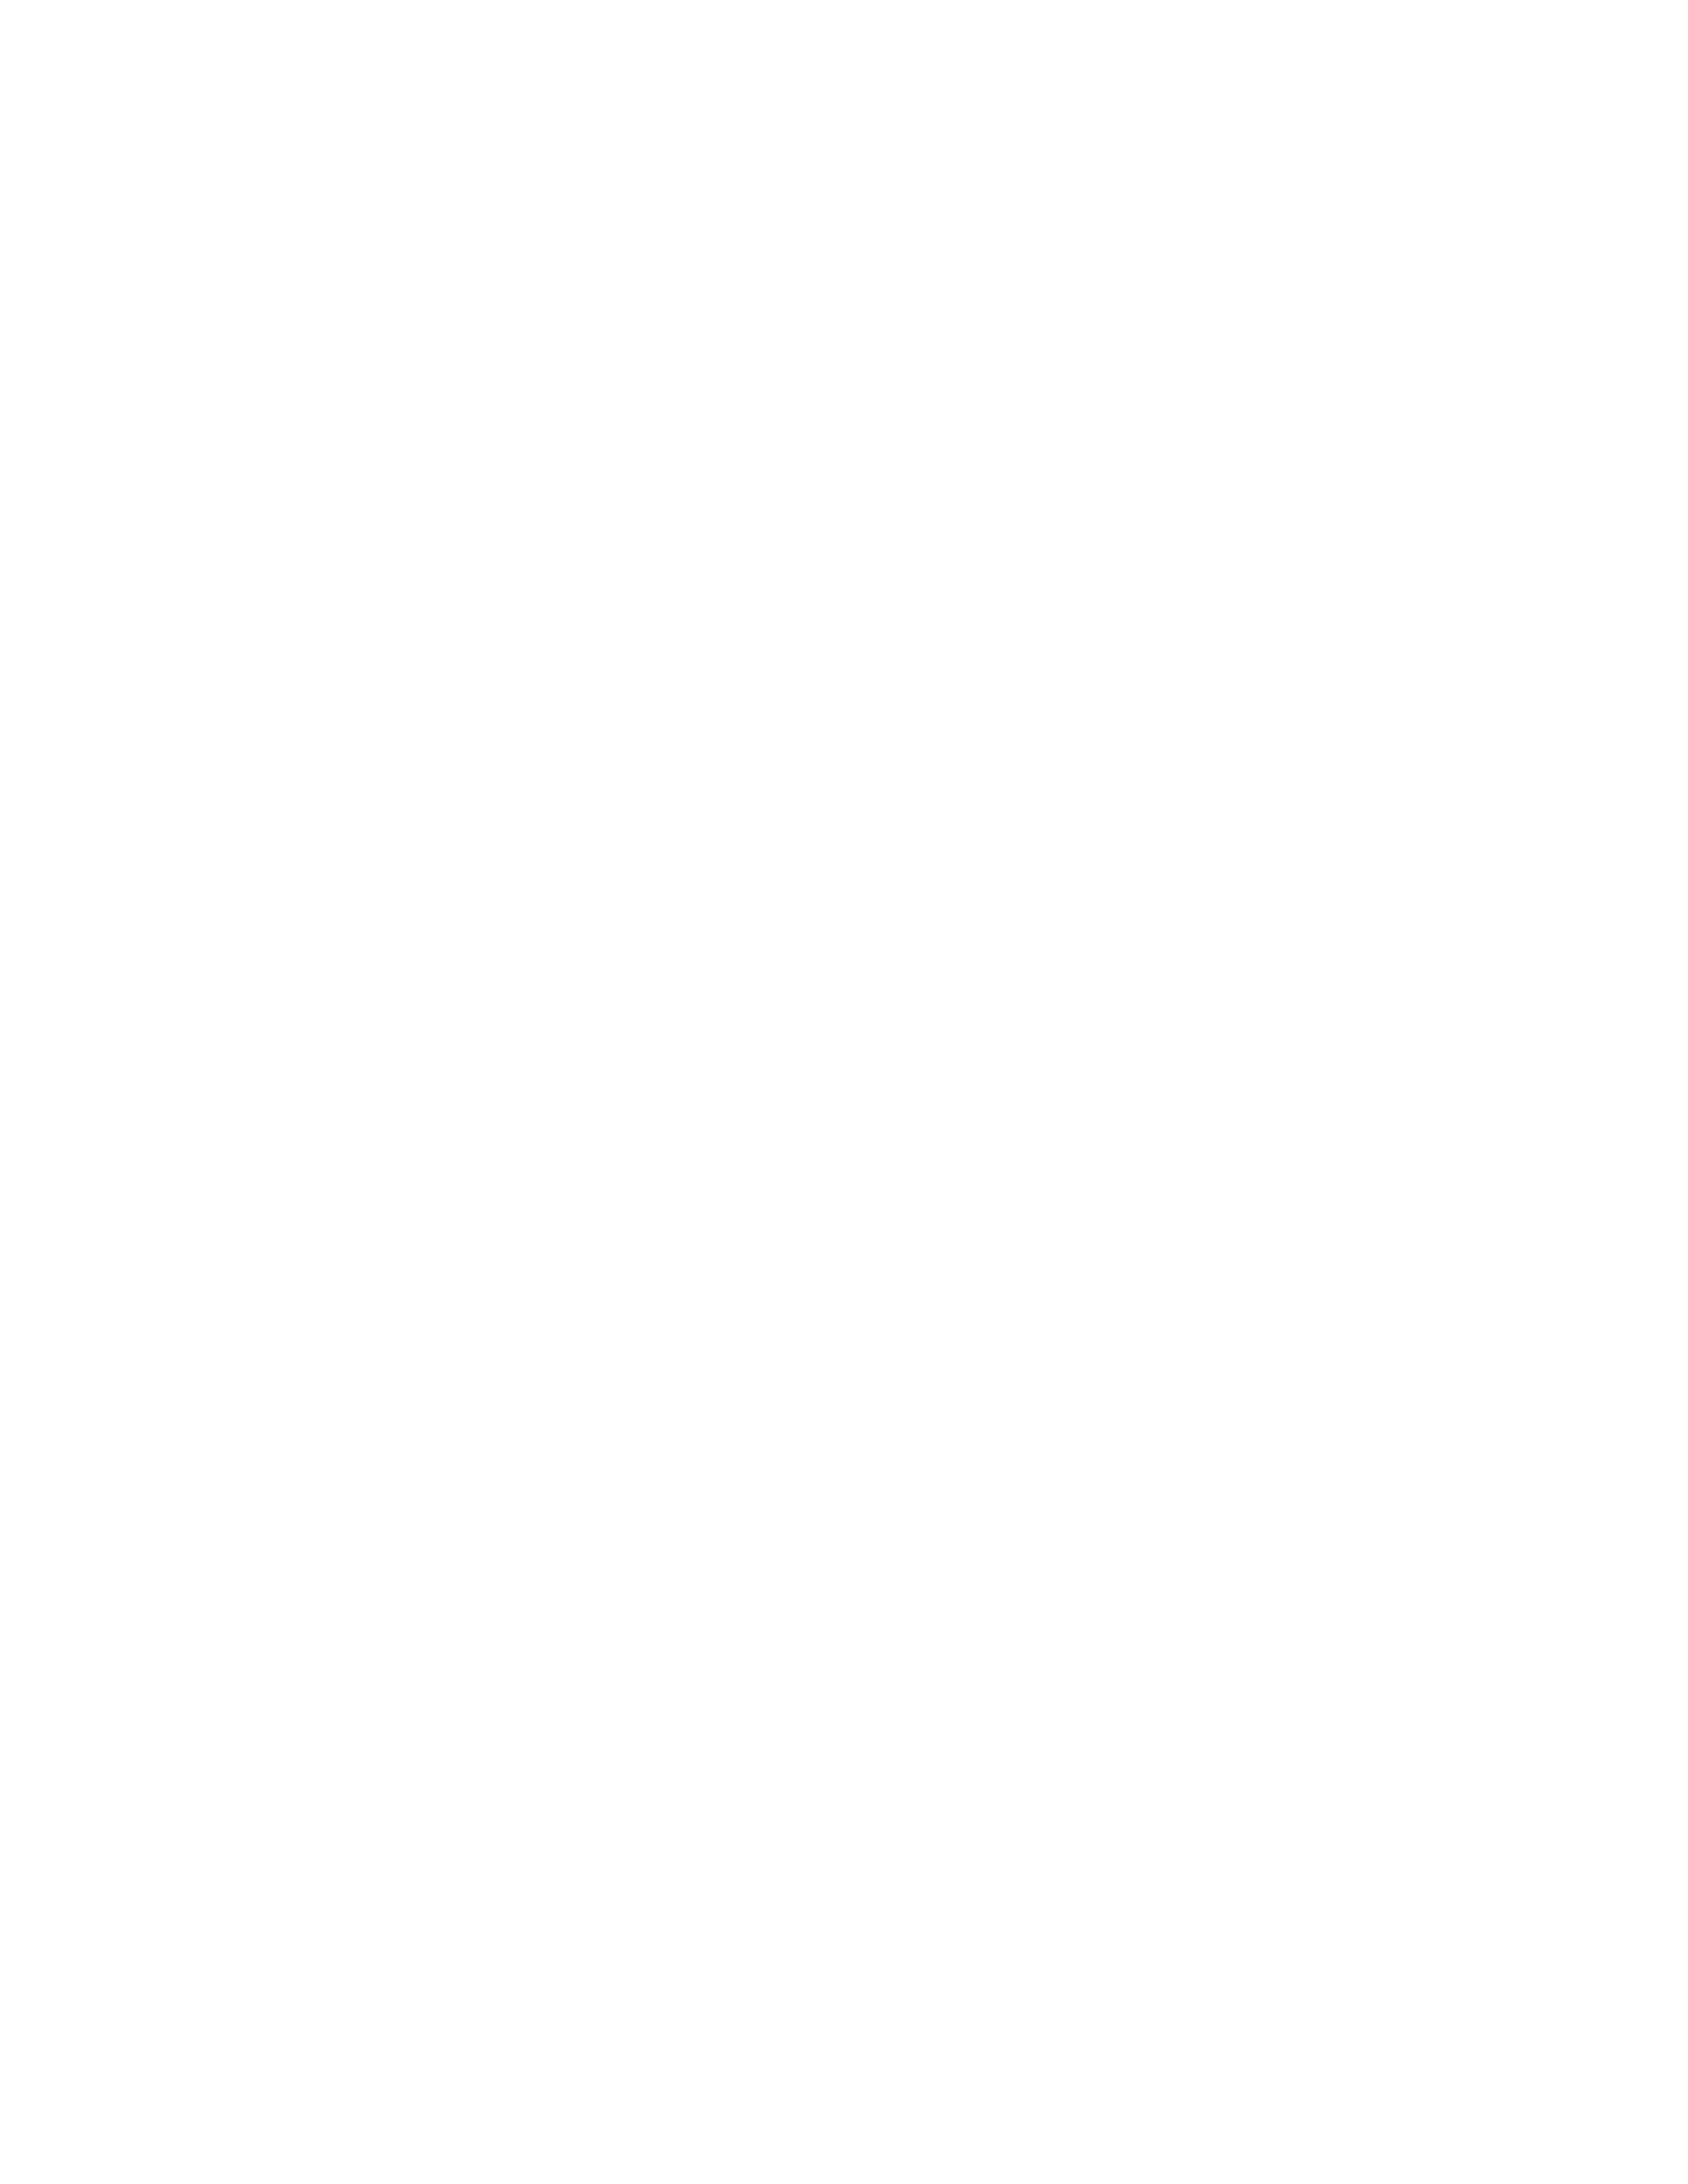

In [9]:
def build_figure3():
    d = pd.read_parquet(DATA)
    with tempfile.TemporaryDirectory() as tmp:
        tmp = Path(tmp)
        schematic = build_schematic(tmp)

        fig = plt.figure(figsize=(W, H))
        panel_a_text(fig)
        check_inset(d, "B", *panel_b(fig, d))
        panel_c(fig, d)
        panel_d(fig, d)
        check_inset(d, "E", *panel_e(fig, d))
        panels_fg(fig, d)
        plots_pdf = tmp / "plots.pdf"
        fig.savefig(plots_pdf, transparent=True)
        plt.close(fig)

        doc = pymupdf.open(plots_pdf)
        page = doc[0]
        rect = pymupdf.Rect(A_X0 * 72, (H - A_TOP) * 72,
                            (A_X0 + A_W) * 72, (H - A_TOP + A_H) * 72)
        page.show_pdf_page(rect, schematic, 0, overlay=False)
        doc.save(f"{OUT_STEM}.pdf", garbage=3, deflate=True)
        page.get_pixmap(dpi=300).save(f"{OUT_STEM}.png")
        doc.close()
        schematic.close()
    print(f"Saved {OUT_STEM}.pdf and .png  ({W * 25.4:.0f} x {H * 25.4:.0f} mm)")


build_figure3()
display(Image(filename=f"{OUT_STEM}.png", width=900))